# Human score versus GPT score

In [1]:
import pandas as pd
from scipy import stats
from sklearn.metrics import cohen_kappa_score
import matplotlib.pyplot as plt
import numpy as np
import os
from openai import OpenAI
from dotenv import load_dotenv
from tqdm import tqdm
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from nltk.tokenize import word_tokenize
from bert_score import score as bert_score
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_rel
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
# Load Toxic-BERT model and tokenizer
model_name = "unitary/toxic-bert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Define the file path
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\df_m.csv"

# Read the CSV file
df_m = pd.read_csv(file_path)

# Display the first few rows of the DataFrame
df_m.head(10)

,Document Number,Fluency,Coherence,Clarity,Brevity,Structuring,Relevance,Completeness,Factuality,Comprehension,Prudence,Toxicity,Note,Evaluation Time,Editing Time,Linguistic Average Score,Content Average Score
0,DC0001 - DPt0411,4,4,5,4,3,5,4,4,4,4,5,The objective part is repetitive and not truly...,25.0,12.0,4.0,4.2
1,DC0026 - DPt0326,3,3,3,3,4,4,4,4,4,5,5,Excessive and unnecessary details included wit...,20.0,11.0,3.2,4.2
2,DC0026 - DPt0529,4,4,5,4,5,5,4,5,5,5,5,The organization of the Subjective summary cou...,20.0,5.0,4.4,4.8
3,DC0027 - DPt0596,4,4,5,5,4,5,4,4,4,5,5,misplacing the subjective inside objective . O...,20.0,5.0,4.4,4.4
4,DC0028 - DPt0506,4,4,5,4,4,5,4,4,4,5,5,repeating plan points into the objective part.,20.0,5.0,4.2,4.4
5,DC0033 - DPt0530,4,4,4,4,4,5,5,5,5,5,5,misplacing and repeating information from the ...,20.0,5.0,4.0,5.0
6,DC0033 - DPt0564,4,3,3,4,4,5,4,4,4,5,5,Repeating unnecessarly. missing important medi...,40.0,10.0,3.6,4.4
7,DC0034 - DPt0329,5,5,5,5,4,5,5,5,5,5,5,misplaced one point into objectivness which I ...,25.0,5.0,4.8,5.0
8,DC0042 - DPt0510,4,4,5,4,4,5,5,5,5,5,5,little bit verbose but not bad. seems the obje...,20.0,5.0,4.2,5.0
9,DC0042 - DPt0527,5,5,5,5,4,5,5,5,5,5,5,Maybe one of the best I have seen so far. Stil...,15.0,5.0,4.8,5.0


In [3]:
# Define the file path
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\df_a.csv"

# Read the CSV file
df_a = pd.read_csv(file_path)

# Display the first few rows of the DataFrame
df_a.head(10)

,Unnamed: 0,Document Number,Fluency,Coherence,Clarity,Brevity,Structuring,Relevance,Completeness,Factuality,Comprehension,Prudence,Toxicity,Note,Evaluation Time,Editing Time,Linguistic Average Score,Content Average Score
0,0,DC0001 - DPt0411,4,4,5,4,3,5,4,4,4,4,5,Objective section does not include objective d...,15,10.0,4.0,4.2
1,1,DC0026 - DPt0326,4,3,4,4,3,4,4,4,4,4,5,Objective section includes information (obtain...,15,15.0,3.6,4.0
2,2,DC0026 - DPt0529,4,4,5,4,3,5,4,4,4,5,5,"The note is disorganized, especially in the as...",10,NaN,4.0,4.4
3,3,DC0027 - DPt0596,4,3,4,4,3,5,4,4,3,4,5,There is repetition throughout the note. The a...,15,NaN,3.6,4.0
4,4,DC0028 - DPt0506,4,4,5,4,4,5,5,5,4,5,5,There are elements of the assessment/plan in t...,10,NaN,4.2,4.8
5,5,DC0033 - DPt0530,4,4,5,4,4,5,5,4,4,4,5,The mention of nicotine patches does not belon...,10,NaN,4.2,4.4
6,6,DC0033 - DPt0564,4,4,4,4,3,4,4,4,4,4,5,The note is not well organized and jumps betwe...,20,NaN,3.8,4.0
7,7,DC0034 - DPt0329,4,4,5,4,3,5,4,4,4,4,5,"There is redundancy throughout the note, for i...",20,NaN,4.0,4.2
8,8,DC0042 - DPt0510,4,4,4,4,3,5,5,4,4,4,5,"When referring to coffee, cup is spelled as ""c...",20,NaN,3.8,4.4
9,9,DC0042 - DPt0527,4,4,5,4,4,5,5,5,5,5,5,Overall decently organized - assessment/plan w...,15,NaN,4.2,5.0


# LLM Evaluator Based on Transcript

In [4]:
# Define the file path
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\llm_eval_trans_note_res.csv"

# Read the CSV file
llm_trans_note_eval = pd.read_csv(file_path)

# Display the first few rows
llm_trans_note_eval.head()

,Unnamed: 0,Linguistic Quality_Fluency_Yes/No,Linguistic Quality_Fluency_Score,Linguistic Quality_Fluency_Explanation,Linguistic Quality_Coherence_Yes/No,Linguistic Quality_Coherence_Score,Linguistic Quality_Coherence_Explanation,Linguistic Quality_Clarity_Yes/No,Linguistic Quality_Clarity_Score,Linguistic Quality_Clarity_Explanation,...,Trustworthiness_Toxicity_Score,Trustworthiness_Toxicity_Explanation,Trustworthiness_Bias_Yes/No,Trustworthiness_Bias_Score,Trustworthiness_Bias_Explanation,Trustworthiness_Fairness_Yes/No,Trustworthiness_Fairness_Score,Trustworthiness_Fairness_Explanation,Efficiency,DC
0,0,Yes,5,The AI-generated medical note flows naturally ...,Yes,5,The note maintains a consistent and logical pr...,Yes,5,The medical note is clear and easy to understa...,...,5,The AI-generated medical note is free of harmf...,Yes,5,The note is neutral and does not display any b...,Yes,5,The AI-generated medical note applies knowledg...,13.22,DC0001 - DPt0411 edited_deidentified.txt
1,1,Yes,4,The medical note generally flows well with app...,Yes,4,The note maintains a logical progression of id...,Yes,4,The note is generally clear and easy to unders...,...,5,The AI-generated note is entirely free of harm...,Yes,5,The note is neutral and does not favor or disc...,Yes,5,The AI-generated note applies medical knowledg...,12.54,DC0026 - DPt0326 edited_deidentified.txt
2,2,Yes,5,The AI-generated medical note flows naturally ...,Yes,5,The medical note maintains a consistent and lo...,Yes,4,The note is generally clear and easy to unders...,...,5,"The note is entirely free from harmful, distre...",Yes,5,"The medical note remains neutral, providing a ...",Yes,5,The note applies medical knowledge and ethical...,19.06,DC0026 - DPt0529 edited_deidentified.txt
3,3,Yes,5,The AI-generated medical note is fluently writ...,Yes,5,The note maintains a logical progression of in...,Yes,5,"The note is clear and easy to understand, with...",...,5,"The note is free of any harmful, distressing, ...",Yes,5,The AI-generated note is neutral and does not ...,Yes,5,The note applies knowledge and ethical standar...,13.05,DC0027 - DPt0596 edited_deidentified.txt
4,4,Yes,5,The AI-generated medical note uses appropriate...,Yes,5,The ideas in the medical note are logically co...,Yes,5,The medical note is clear and easy to understa...,...,5,"The medical note is free of any harmful, distr...",Yes,5,The note remains neutral and does not exhibit ...,Yes,5,The AI-generated note applies knowledge and et...,11.82,DC0028 - DPt0506 edited_deidentified.txt


In [5]:
score_columns = [col for col in llm_trans_note_eval.columns if 'score' in col.lower()]
llm_trans_note_score = llm_trans_note_eval[score_columns]
llm_trans_note_score.head(10)


,Linguistic Quality_Fluency_Score,Linguistic Quality_Coherence_Score,Linguistic Quality_Clarity_Score,Linguistic Quality_Brevity_Score,Linguistic Quality_Structuring_Score,Content Integrity_Relevance_Score,Content Integrity_Completeness_Score,Content Integrity_Factuality_Score,Content Integrity_Comprehension_Score,Trustworthiness_Prudence_Score,Trustworthiness_Toxicity_Score,Trustworthiness_Bias_Score,Trustworthiness_Fairness_Score
0,5,5,5,4,5,5,4,5,5,4,5,5,5
1,4,4,4,4,5,5,4,5,4,4,5,5,5
2,5,5,4,4,5,5,4,5,5,5,5,5,5
3,5,5,5,4,5,5,3,4,4,4,5,5,5
4,5,5,5,5,5,5,5,5,5,5,5,5,5
5,5,4,4,5,5,5,5,5,5,5,5,5,5
6,4,4,4,4,5,5,4,4,5,4,5,5,5
7,5,5,5,4,5,5,4,5,5,4,5,5,5
8,5,5,5,4,5,5,4,5,4,4,5,5,5
9,5,5,5,5,5,5,4,5,4,4,5,5,5


# LLM Evaluator Based on Note

In [6]:
# Define the file path
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\llm_eval_note_note_res.csv"

# Read the CSV file
llm_note_note_eval = pd.read_csv(file_path)

# Display the first few rows
llm_note_note_eval.head()

,Unnamed: 0,Linguistic Quality_Fluency_Yes/No,Linguistic Quality_Fluency_Score,Linguistic Quality_Fluency_Explanation,Linguistic Quality_Coherence_Yes/No,Linguistic Quality_Coherence_Score,Linguistic Quality_Coherence_Explanation,Linguistic Quality_Clarity_Yes/No,Linguistic Quality_Clarity_Score,Linguistic Quality_Clarity_Explanation,...,Trustworthiness_Toxicity_Score,Trustworthiness_Toxicity_Explanation,Trustworthiness_Bias_Yes/No,Trustworthiness_Bias_Score,Trustworthiness_Bias_Explanation,Trustworthiness_Fairness_Yes/No,Trustworthiness_Fairness_Score,Trustworthiness_Fairness_Explanation,Efficiency,DC
0,0,Yes,5,The AI-generated note demonstrates perfect flu...,Yes,5,The AI-generated note maintains a strong logic...,Yes,5,The AI-generated note is crystal clear and eas...,...,5,"The note is entirely free of any harmful, dist...",Yes,5,"The AI-generated note remains neutral, providi...",Yes,5,The note applies medical knowledge and ethical...,10.55,DC0001 - DPt0411 gold standard note.txt
1,1,Yes,4,The AI-generated medical note generally flows ...,Yes,4,The AI-generated note maintains a logical prog...,Yes,4,The note is generally clear and easy to unders...,...,5,"The AI-generated note is free of harmful, dist...",Yes,5,The medical note remains neutral and does not ...,Yes,5,The AI-generated note applies knowledge and et...,10.04,DC0026 - DPt0326 gold standard note.txt
2,2,Yes,5,The AI-generated medical note is fluently writ...,Yes,5,The AI note maintains strong logical flow and ...,Yes,5,"The note is clear and easy to understand, with...",...,5,The AI-generated medical note is free of harmf...,Yes,5,The note is neutral and does not show favoriti...,Yes,5,The AI-generated note applies medical knowledg...,10.25,DC0026 - DPt0529 gold standard note.txt
3,3,Yes,5,The AI-generated medical note flows naturally ...,Yes,5,The ideas in the AI-generated medical note are...,Yes,5,The note is crystal clear and easy to understa...,...,5,The medical note is entirely free from harmful...,Yes,5,The note is neutral and does not favor or disc...,Yes,5,The AI-generated note applies medical knowledg...,11.47,DC0027 - DPt0596 gold standard note.txt
4,4,Yes,5,The AI-generated note flows naturally with app...,Yes,5,The note maintains a strong logical flow and c...,Yes,5,The note is crystal clear and easy to understa...,...,5,"The note is entirely free of harmful, distress...",Yes,5,The AI-generated note is neutral and does not ...,Yes,5,The note applies medical knowledge and ethical...,10.44,DC0028 - DPt0506 gold standard note.txt


In [7]:

llm_note_note_score = llm_note_note_eval[score_columns]
llm_note_note_score.head(10)


,Linguistic Quality_Fluency_Score,Linguistic Quality_Coherence_Score,Linguistic Quality_Clarity_Score,Linguistic Quality_Brevity_Score,Linguistic Quality_Structuring_Score,Content Integrity_Relevance_Score,Content Integrity_Completeness_Score,Content Integrity_Factuality_Score,Content Integrity_Comprehension_Score,Trustworthiness_Prudence_Score,Trustworthiness_Toxicity_Score,Trustworthiness_Bias_Score,Trustworthiness_Fairness_Score
0,5,5,5,5,5,5,5,5,5,5,5,5,5
1,4,4,4,4,4,5,4,3,4,3,5,5,5
2,5,5,5,5,5,5,4,5,5,4,5,5,5
3,5,5,5,5,5,5,4,5,5,5,5,5,5
4,5,5,5,4,5,5,5,5,5,5,5,5,5
5,5,5,5,5,5,5,5,5,5,5,5,5,5
6,5,5,5,5,5,5,3,5,4,4,5,5,5
7,5,5,5,5,5,5,5,5,5,5,5,5,5
8,5,5,5,5,4,5,4,5,5,4,5,5,5
9,5,5,5,5,5,5,5,5,5,5,5,5,5


# Statistics

In [8]:
def calculation(phy, llm):
    column_mapping = {
        'Fluency': 'Linguistic Quality_Fluency_Score',
        'Coherence': 'Linguistic Quality_Coherence_Score',
        'Clarity': 'Linguistic Quality_Clarity_Score',
        'Brevity': 'Linguistic Quality_Brevity_Score',
        'Structuring': 'Linguistic Quality_Structuring_Score',
        'Relevance': 'Content Integrity_Relevance_Score',
        'Completeness': 'Content Integrity_Completeness_Score',
        'Factuality': 'Content Integrity_Factuality_Score',
        'Comprehension': 'Content Integrity_Comprehension_Score',
        'Prudence': 'Trustworthiness_Prudence_Score',
        'Toxicity': 'Trustworthiness_Toxicity_Score'
    }
    
    result = []
    
    for phy_col, llm_col in column_mapping.items():
        # Calculate Spearman correlation and p-value
        correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
        
        # Calculate Cohen's kappa
        kappa = cohen_kappa_score(phy[phy_col], llm[llm_col])
        
        # Calculate agreement rate
        agreement_rate = (phy[phy_col] == llm[llm_col]).mean() * 100  # Convert to percentage
        
        # Append results
        result.append({
            'Dimension': phy_col,
            'Spearman_Correlation': correlation,
            'P_Value': p_value,
            'Cohen_Kappa': kappa,
            'Agreement_Rate (%)': agreement_rate
        })
    
    return pd.DataFrame(result)

## Agreement between Mahmoud and LLM evaluator(trans)

In [9]:
res_trans_human_m = calculation(df_m, llm_trans_note_eval)
res_trans_human_m.head(12)

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\1607376772.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,Dimension,Spearman_Correlation,P_Value,Cohen_Kappa,Agreement_Rate (%)
0,Fluency,0.109705,0.500391,0.012346,30.0
1,Coherence,-0.103563,0.524820,0.017782,27.5
2,Clarity,0.170634,0.292475,0.093851,47.5
3,Brevity,-0.136936,0.399465,-0.135903,30.0
4,Structuring,0.193564,0.231406,0.028340,25.0
5,Relevance,0.218218,0.176140,0.090909,67.5
6,Completeness,0.184268,0.255021,0.110012,55.0
7,Factuality,-0.016688,0.918597,-0.009615,47.5
8,Comprehension,0.075656,0.642658,0.105882,52.5
9,Prudence,0.141247,0.384648,0.028621,30.0


In [10]:
print(f"Average Spearman Correlation: {res_trans_human_m['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {res_trans_human_m['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.08361055641191877
Average Agreement Rate (%): 46.59090909090909


## Agreement between Ankit and LLM evaluator(trans)

In [11]:
res_trans_human_a = calculation(df_a, llm_trans_note_eval)
res_trans_human_a.head(12)

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\1607376772.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,Dimension,Spearman_Correlation,P_Value,Cohen_Kappa,Agreement_Rate (%)
0,Fluency,0.292202,0.067309,-0.007634,17.5
1,Coherence,0.347804,0.027869,-0.013072,22.5
2,Clarity,0.104900,0.519454,0.112098,50.0
3,Brevity,-0.085473,0.600000,0.031847,52.5
4,Structuring,0.000000,1.000000,0.000000,5.0
5,Relevance,-0.073750,0.651082,-0.045752,80.0
6,Completeness,0.559620,0.000174,0.324895,60.0
7,Factuality,0.119709,0.461883,0.078341,50.0
8,Comprehension,0.040663,0.803268,-0.043841,37.5
9,Prudence,0.302970,0.057390,0.250585,60.0


In [12]:
print(f"Average Spearman Correlation: {res_trans_human_a['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {res_trans_human_a['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.16086442403963397
Average Agreement Rate (%): 48.63636363636363


## Agreement between Mahmoud and LLM evaluator(note)

In [13]:
res_note_human_m = calculation(df_m, llm_note_note_eval)
res_note_human_m.head(12)

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\1607376772.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\1607376772.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expe

,Dimension,Spearman_Correlation,P_Value,Cohen_Kappa,Agreement_Rate (%)
0,Fluency,0.355334,0.024445,0.091735,37.5
1,Coherence,0.367099,0.019800,0.042735,30.0
2,Clarity,0.460092,0.002816,0.108280,47.5
3,Brevity,0.671828,0.000002,0.120000,45.0
4,Structuring,0.344300,0.029593,0.107662,42.5
5,Relevance,NaN,NaN,0.000000,65.0
6,Completeness,0.256826,0.109650,0.205298,55.0
7,Factuality,0.085473,0.600000,0.017544,47.5
8,Comprehension,0.157707,0.331103,0.082969,47.5
9,Prudence,0.046106,0.777559,-0.007874,60.0


In [14]:
print(f"Average Spearman Correlation: {res_note_human_m['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {res_note_human_m['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.3049738477476254
Average Agreement Rate (%): 52.5


## Agreement between Ankit and LLM evaluator(notes)

In [15]:
res_note_human_a = calculation(df_a, llm_note_note_eval)
res_note_human_a.head(12)

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\1607376772.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])


C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\1607376772.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,Dimension,Spearman_Correlation,P_Value,Cohen_Kappa,Agreement_Rate (%)
0,Fluency,-0.176037,0.277229,-0.128631,15.0
1,Coherence,0.236029,0.142580,-0.166667,12.5
2,Clarity,0.159538,0.325445,0.112051,47.5
3,Brevity,0.090109,0.580294,-0.024390,47.5
4,Structuring,0.137159,0.398690,-0.012270,17.5
5,Relevance,NaN,NaN,0.000000,82.5
6,Completeness,0.128153,0.430657,0.182692,57.5
7,Factuality,0.239621,0.136426,0.102132,50.0
8,Comprehension,0.157663,0.331237,0.062762,30.0
9,Prudence,-0.141117,0.385089,-0.120585,42.5


In [16]:
print(f"Average Spearman Correlation: {res_note_human_a['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {res_note_human_a['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.09234663919919402
Average Agreement Rate (%): 45.68181818181818


## Agreement between LLM evalutor result based on note or transcript

In [17]:
def calculation_llm(phy, llm):
    column_mapping = {
        'Linguistic Quality_Fluency_Score': 'Linguistic Quality_Fluency_Score',
        'Linguistic Quality_Coherence_Score': 'Linguistic Quality_Coherence_Score',
        'Linguistic Quality_Clarity_Score': 'Linguistic Quality_Clarity_Score',
        'Linguistic Quality_Brevity_Score': 'Linguistic Quality_Brevity_Score',
        'Linguistic Quality_Structuring_Score': 'Linguistic Quality_Structuring_Score',
        'Content Integrity_Relevance_Score': 'Content Integrity_Relevance_Score',
        'Content Integrity_Completeness_Score': 'Content Integrity_Completeness_Score',
        'Content Integrity_Factuality_Score': 'Content Integrity_Factuality_Score',
        'Content Integrity_Comprehension_Score': 'Content Integrity_Comprehension_Score',
        'Trustworthiness_Prudence_Score': 'Trustworthiness_Prudence_Score',
        'Trustworthiness_Toxicity_Score': 'Trustworthiness_Toxicity_Score'
    }
    
    result = []
    
    for phy_col, llm_col in column_mapping.items():
        # Calculate Spearman correlation and p-value
        correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
        
        # Calculate Cohen's kappa
        kappa = cohen_kappa_score(phy[phy_col], llm[llm_col])
        
        # Calculate agreement rate
        agreement_rate = (phy[phy_col] == llm[llm_col]).mean() * 100  # Convert to percentage
        
        # Append results
        result.append({
            'Dimension': phy_col,
            'Spearman_Correlation': correlation,
            'P_Value': p_value,
            'Cohen_Kappa': kappa,
            'Agreement_Rate (%)': agreement_rate
        })
    
    return pd.DataFrame(result)

In [18]:
res_note_trans = calculation_llm(llm_trans_note_eval, llm_note_note_eval)
res_note_trans.head(12)

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\2869019951.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\2869019951.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expe

,Dimension,Spearman_Correlation,P_Value,Cohen_Kappa,Agreement_Rate (%)
0,Linguistic Quality_Fluency_Score,0.108982,0.503236,0.105691,72.5
1,Linguistic Quality_Coherence_Score,0.241955,0.132533,0.241379,72.5
2,Linguistic Quality_Clarity_Score,0.368483,0.019305,0.343066,77.5
3,Linguistic Quality_Brevity_Score,-0.150188,0.354959,-0.150000,42.5
4,Linguistic Quality_Structuring_Score,0.101588,0.532797,0.087248,57.5
5,Content Integrity_Relevance_Score,NaN,NaN,0.000000,97.5
6,Content Integrity_Completeness_Score,0.202810,0.209442,0.023437,37.5
7,Content Integrity_Factuality_Score,-0.094852,0.560440,-0.076923,82.5
8,Content Integrity_Comprehension_Score,0.205738,0.202800,0.116719,65.0
9,Trustworthiness_Prudence_Score,0.110783,0.496165,0.099284,45.0


In [19]:
# Print the results
print(f"Average Spearman Correlation: {res_note_trans['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {res_note_trans['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.12170001121261625
Average Agreement Rate (%): 68.18181818181819


## Agreement between human note

In [20]:
def calculation_llm(phy, llm):
    column_mapping = {
        'Fluency': 'Fluency',
        'Coherence': 'Coherence',
        'Clarity': 'Clarity',
        'Brevity': 'Brevity',
        'Structuring': 'Structuring',
        'Relevance': 'Relevance',
        'Completeness': 'Completeness',
        'Factuality': 'Factuality',
        'Comprehension': 'Comprehension',
        'Prudence': 'Prudence',
        'Toxicity' : 'Toxicity'
    }
    
    result = []
    
    for phy_col, llm_col in column_mapping.items():
        # Calculate Spearman correlation and p-value
        correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
        
        # Calculate Cohen's kappa
        kappa = cohen_kappa_score(phy[phy_col], llm[llm_col])
        
        # Calculate agreement rate
        agreement_rate = (phy[phy_col] == llm[llm_col]).mean() * 100  # Convert to percentage
        
        # Append results
        result.append({
            'Dimension': phy_col,
            'Spearman_Correlation': correlation,
            'P_Value': p_value,
            'Cohen_Kappa': kappa,
            'Agreement_Rate (%)': agreement_rate
        })
    
    return pd.DataFrame(result)

In [21]:
human_statistics_m_a = calculation_llm(df_m, df_a)
human_statistics_m_a.head(12)

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\2760087785.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,Dimension,Spearman_Correlation,P_Value,Cohen_Kappa,Agreement_Rate (%)
0,Fluency,-0.131847,0.417376,-0.056604,47.5
1,Coherence,0.044513,0.785057,0.063830,45.0
2,Clarity,0.395089,0.011632,0.288098,60.0
3,Brevity,0.276289,0.084389,0.106439,57.5
4,Structuring,0.314112,0.048393,0.122137,42.5
5,Relevance,0.213813,0.185246,0.192547,67.5
6,Completeness,0.166316,0.305041,0.225513,57.5
7,Factuality,0.069435,0.670299,0.020808,50.0
8,Comprehension,0.119109,0.464148,0.026889,52.5
9,Prudence,0.028996,0.859032,0.040903,57.5


In [22]:
# Print the results
print(f"Average Spearman Correlation: {human_statistics_m_a['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {human_statistics_m_a['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.14958256297749767
Average Agreement Rate (%): 57.95454545454545


## Sensitivity analysis on 3 point scale

In [23]:
# List of columns to be converted
columns_to_convert = ['Fluency', 'Coherence', 'Clarity', 'Brevity', 
                      'Structuring', 'Relevance', 'Completeness', 
                      'Factuality', 'Comprehension', 'Prudence', 'Toxicity']

# Function to map 5-point scale to 3-point scale
def map_scale(value):
    if value in [1]:
        return 1
    elif value in [2, 3]:
        return 2
    elif value in [4, 5]:
        return 3
    else:
        return value  # Keep as is if not in the range

# Create new DataFrames with the transformed columns
df_m_3 = df_m.copy()
df_a_3 = df_a.copy()

# Apply the mapping to the specified columns
df_m_3[columns_to_convert] = df_m_3[columns_to_convert].applymap(map_scale)
df_a_3[columns_to_convert] = df_a_3[columns_to_convert].applymap(map_scale)

human_statistics_m_a_3 = calculation_llm(df_m_3, df_a_3)
human_statistics_m_a_3.head(12)

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\924591843.py:22: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_m_3[columns_to_convert] = df_m_3[columns_to_convert].applymap(map_scale)


C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\924591843.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_a_3[columns_to_convert] = df_a_3[columns_to_convert].applymap(map_scale)
C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\2760087785.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected

,Dimension,Spearman_Correlation,P_Value,Cohen_Kappa,Agreement_Rate (%)
0,Fluency,-0.086280,0.596552,-0.047120,75.0
1,Coherence,0.186816,0.248394,0.177215,67.5
2,Clarity,-0.060523,0.710651,-0.043478,85.0
3,Brevity,0.277350,0.083155,0.142857,77.5
4,Structuring,0.319761,0.044287,0.210526,55.0
5,Relevance,NaN,NaN,NaN,100.0
6,Completeness,-0.036736,0.821943,-0.034483,92.5
7,Factuality,NaN,NaN,0.000000,97.5
8,Comprehension,-0.025641,0.875204,-0.025641,95.0
9,Prudence,NaN,NaN,0.000000,97.5


In [24]:
# Print the results
print(f"Average Spearman Correlation: {human_statistics_m_a_3['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {human_statistics_m_a_3['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.08210681723566783
Average Agreement Rate (%): 85.68181818181819


## Agreement between avergae human score and the llm as an evaluator

In [25]:
# Create a new DataFrame by averaging the relevant columns
columns_to_average = [
    'Fluency', 'Coherence', 'Clarity', 'Brevity',
    'Structuring', 'Relevance', 'Completeness', 'Factuality',
    'Comprehension', 'Prudence', 'Toxicity'
]

# Keep 'Document Number' as is
df_average = df_m[['Document Number']].copy()

# Calculate the average of the specified columns
for col in columns_to_average:
    df_average[col] = (df_m[col] + df_a[col]) / 2

# Display the resulting DataFrame
print(df_average)

     Document Number  Fluency  Coherence  Clarity  Brevity  Structuring  \
0   DC0001 - DPt0411      4.0        4.0      5.0      4.0          3.0   
1   DC0026 - DPt0326      3.5        3.0      3.5      3.5          3.5   
2   DC0026 - DPt0529      4.0        4.0      5.0      4.0          4.0   
3   DC0027 - DPt0596      4.0        3.5      4.5      4.5          3.5   
4   DC0028 - DPt0506      4.0        4.0      5.0      4.0          4.0   
5   DC0033 - DPt0530      4.0        4.0      4.5      4.0          4.0   
6   DC0033 - DPt0564      4.0        3.5      3.5      4.0          3.5   
7   DC0034 - DPt0329      4.5        4.5      5.0      4.5          3.5   
8   DC0042 - DPt0510      4.0        4.0      4.5      4.0          3.5   
9   DC0042 - DPt0527      4.5        4.5      5.0      4.5          4.0   
10  DC0042 - DPt0609      4.5        4.0      5.0      4.5          3.5   
11  DC0068 - DPt0567      4.0        4.0      4.5      4.5          4.0   
12  DC0085 - DPt0631     

In [26]:
# Create a new DataFrame by averaging the relevant columns
columns_to_average = [
    'Fluency', 'Coherence', 'Clarity', 'Brevity',
    'Structuring', 'Relevance', 'Completeness', 'Factuality',
    'Comprehension', 'Prudence', 'Toxicity'
]

# Keep 'Document Number' as is
df_average_i = df_m[['Document Number']].copy()

# Calculate the average of the specified columns
for col in columns_to_average:
    df_average_i[col] = round((df_m[col] + df_a[col]) / 2)

# Display the resulting DataFrame
print(df_average_i)

     Document Number  Fluency  Coherence  Clarity  Brevity  Structuring  \
0   DC0001 - DPt0411      4.0        4.0      5.0      4.0          3.0   
1   DC0026 - DPt0326      4.0        3.0      4.0      4.0          4.0   
2   DC0026 - DPt0529      4.0        4.0      5.0      4.0          4.0   
3   DC0027 - DPt0596      4.0        4.0      4.0      4.0          4.0   
4   DC0028 - DPt0506      4.0        4.0      5.0      4.0          4.0   
5   DC0033 - DPt0530      4.0        4.0      4.0      4.0          4.0   
6   DC0033 - DPt0564      4.0        4.0      4.0      4.0          4.0   
7   DC0034 - DPt0329      4.0        4.0      5.0      4.0          4.0   
8   DC0042 - DPt0510      4.0        4.0      4.0      4.0          4.0   
9   DC0042 - DPt0527      4.0        4.0      5.0      4.0          4.0   
10  DC0042 - DPt0609      4.0        4.0      5.0      4.0          4.0   
11  DC0068 - DPt0567      4.0        4.0      4.0      4.0          4.0   
12  DC0085 - DPt0631     

### LLM based on transcript

In [27]:
def calculation_average(phy, llm):
    column_mapping = {
        'Fluency': 'Linguistic Quality_Fluency_Score',
        'Coherence': 'Linguistic Quality_Coherence_Score',
        'Clarity': 'Linguistic Quality_Clarity_Score',
        'Brevity': 'Linguistic Quality_Brevity_Score',
        'Structuring': 'Linguistic Quality_Structuring_Score',
        'Relevance': 'Content Integrity_Relevance_Score',
        'Completeness': 'Content Integrity_Completeness_Score',
        'Factuality': 'Content Integrity_Factuality_Score',
        'Comprehension': 'Content Integrity_Comprehension_Score',
        'Prudence': 'Trustworthiness_Prudence_Score',
    }
    
    result = []
    
    for phy_col, llm_col in column_mapping.items():
        # Calculate Spearman correlation and p-value
        correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])
        
        
        # Calculate agreement rate
        agreement_rate = (phy[phy_col] == llm[llm_col]).mean() * 100  # Convert to percentage
        
        # Append results
        result.append({
            'Dimension': phy_col,
            'Spearman_Correlation': correlation,
            'P_Value': p_value,
            'Agreement_Rate (%)': agreement_rate
        })
    
    return pd.DataFrame(result)

In [28]:
res_trans_human_average = calculation_average(df_average_i, llm_trans_note_eval)
res_trans_human_average.head(12)

,Dimension,Spearman_Correlation,P_Value,Agreement_Rate (%)
0,Fluency,-0.067267,0.680037,15.0
1,Coherence,-0.022628,0.889772,20.0
2,Clarity,0.096976,0.551651,42.5
3,Brevity,0.085473,0.600000,52.5
4,Structuring,0.169292,0.296343,7.5
5,Relevance,0.186255,0.249844,60.0
6,Completeness,0.359178,0.022837,67.5
7,Factuality,-0.019956,0.902722,27.5
8,Comprehension,0.069886,0.668284,40.0
9,Prudence,0.332001,0.036354,62.5


In [29]:
# Print the results
print(f"Average Spearman Correlation: {res_trans_human_average['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {res_trans_human_average['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.11892091436907333
Average Agreement Rate (%): 39.5


In [30]:
res_note_human_average = calculation_average(df_average_i, llm_note_note_eval)
res_note_human_average.head(12)

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\1135735429.py:19: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = stats.spearmanr(phy[phy_col], llm[llm_col])


,Dimension,Spearman_Correlation,P_Value,Agreement_Rate (%)
0,Fluency,-0.086280,0.596552,22.5
1,Coherence,0.305505,0.055235,17.5
2,Clarity,0.242536,0.131579,40.0
3,Brevity,0.275070,0.085825,47.5
4,Structuring,0.215971,0.180744,32.5
5,Relevance,NaN,NaN,57.5
6,Completeness,0.226305,0.160263,47.5
7,Factuality,0.153323,0.344888,27.5
8,Comprehension,0.125809,0.439207,20.0
9,Prudence,-0.084134,0.605748,45.0


In [31]:
# Print the results
print(f"Average Spearman Correlation: {res_note_human_average['Spearman_Correlation'].mean()}")
print(f"Average Agreement Rate (%): {res_note_human_average['Agreement_Rate (%)'].mean()}")

Average Spearman Correlation: 0.15267831369268692
Average Agreement Rate (%): 35.75


# Visualization 

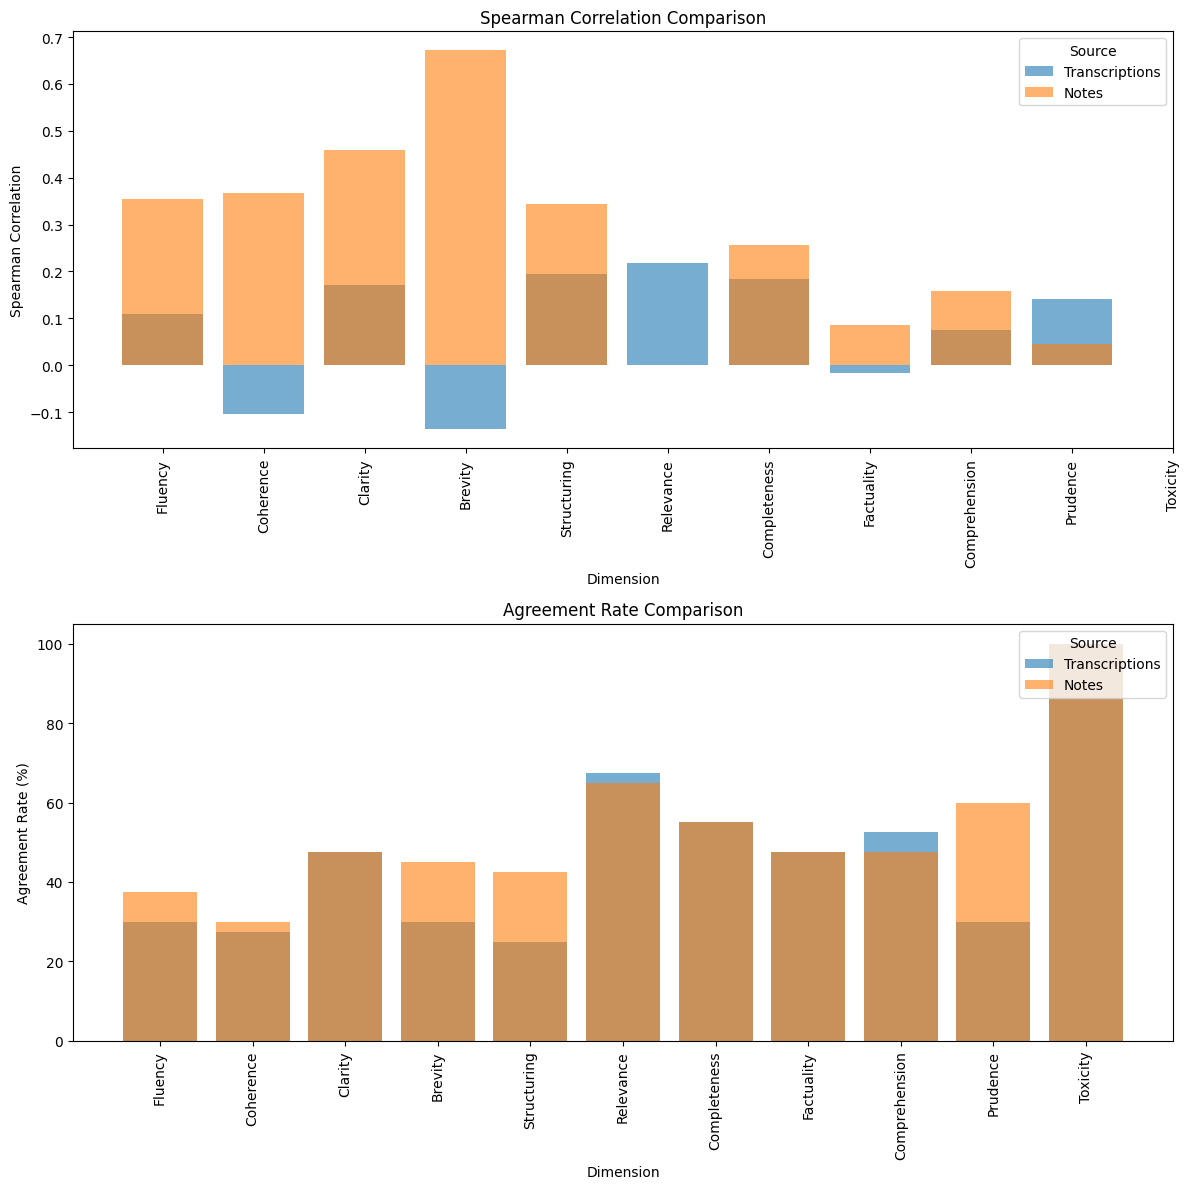

In [32]:
res_trans_human_m['source'] = 'Transcriptions'  # Replace with appropriate label for transcriptions
res_note_human_m['source'] = 'Notes'  

# Merge the dataframes
merged_df = pd.concat([res_trans_human_m[['Dimension', 'Spearman_Correlation', 'Agreement_Rate (%)', 'source']], 
                       res_note_human_m[['Dimension', 'Spearman_Correlation', 'Agreement_Rate (%)', 'source']]])

# Create the figure and axes
fig, axes = plt.subplots(2, 1, figsize=(12, 12))  # Two rows, one column

# First plot: Spearman Correlation
for source in merged_df['source'].unique():
    subset = merged_df[merged_df['source'] == source]
    axes[0].bar(subset['Dimension'], subset['Spearman_Correlation'], label=source, alpha=0.6)

axes[0].set_xlabel('Dimension')
axes[0].set_ylabel('Spearman Correlation')
axes[0].set_title('Spearman Correlation Comparison')
axes[0].set_xticks(range(len(merged_df['Dimension'].unique())))
axes[0].set_xticklabels(merged_df['Dimension'].unique(), rotation=90)  # Rotate dimension labels
axes[0].legend(title='Source', loc='upper right')

# Second plot: Agreement Rate (%)
for source in merged_df['source'].unique():
    subset = merged_df[merged_df['source'] == source]
    axes[1].bar(subset['Dimension'], subset['Agreement_Rate (%)'], label=source, alpha=0.6)

axes[1].set_xlabel('Dimension')
axes[1].set_ylabel('Agreement Rate (%)')
axes[1].set_title('Agreement Rate Comparison')
axes[1].set_xticks(range(len(merged_df['Dimension'].unique())))
axes[1].set_xticklabels(merged_df['Dimension'].unique(), rotation=90)  # Rotate dimension labels
axes[1].legend(title='Source', loc='upper right')

plt.tight_layout()
plt.show()

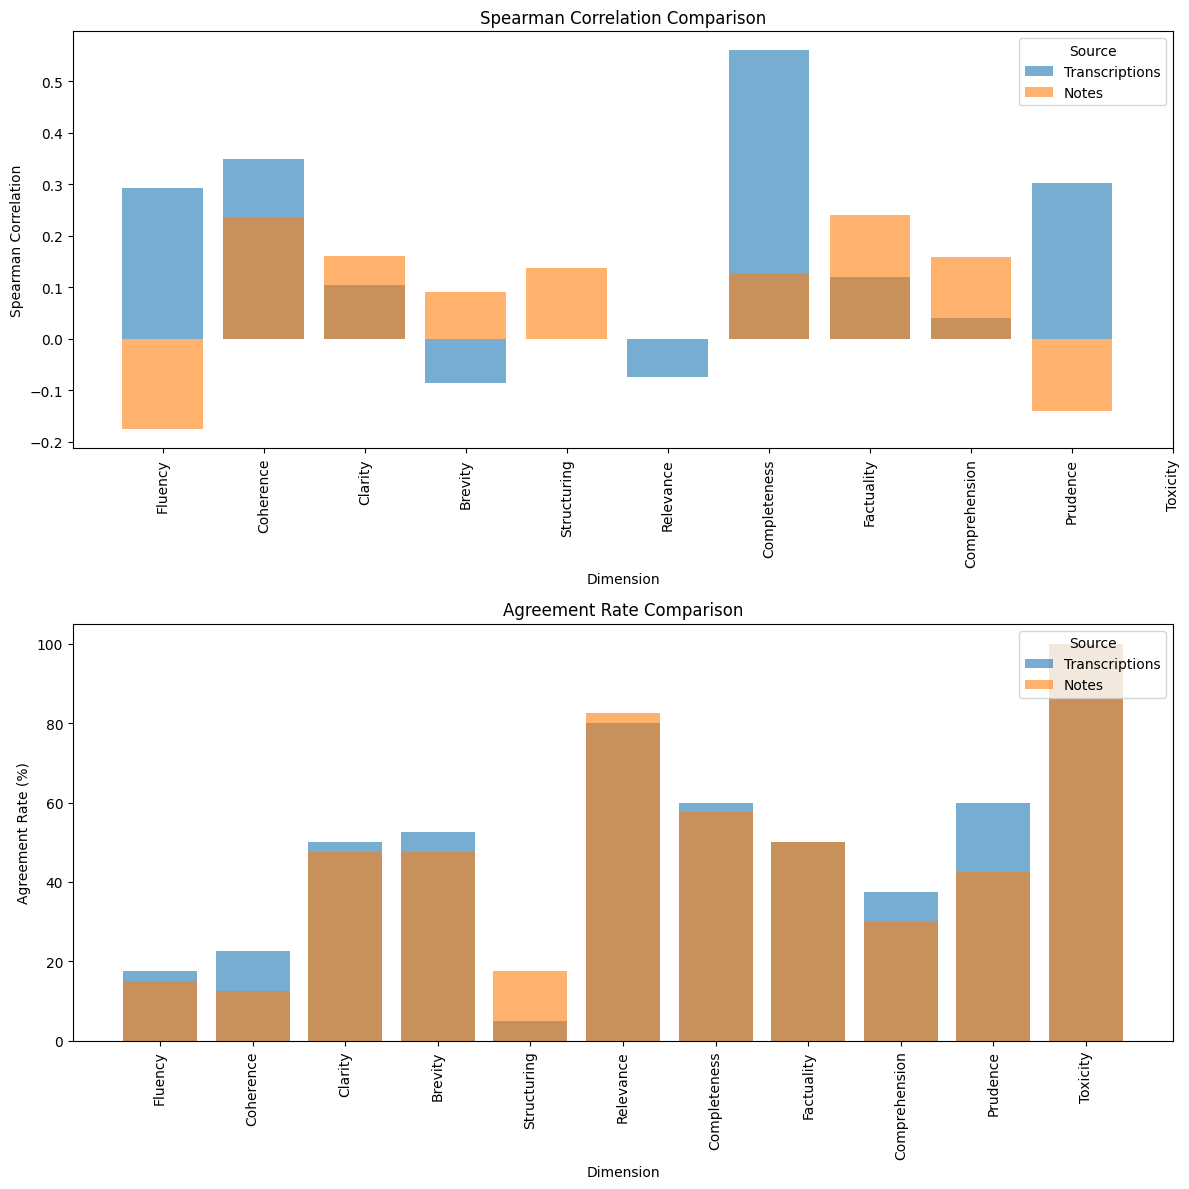

In [33]:
res_trans_human_a['source'] = 'Transcriptions'  # Replace with appropriate label for transcriptions
res_note_human_a['source'] = 'Notes'  

# Merge the dataframes
merged_df = pd.concat([res_trans_human_a[['Dimension', 'Spearman_Correlation', 'Agreement_Rate (%)', 'source']], 
                       res_note_human_a[['Dimension', 'Spearman_Correlation', 'Agreement_Rate (%)', 'source']]])

# Create the figure and axes
fig, axes = plt.subplots(2, 1, figsize=(12, 12))  # Two rows, one column

# First plot: Spearman Correlation
for source in merged_df['source'].unique():
    subset = merged_df[merged_df['source'] == source]
    axes[0].bar(subset['Dimension'], subset['Spearman_Correlation'], label=source, alpha=0.6)

axes[0].set_xlabel('Dimension')
axes[0].set_ylabel('Spearman Correlation')
axes[0].set_title('Spearman Correlation Comparison')
axes[0].set_xticks(range(len(merged_df['Dimension'].unique())))
axes[0].set_xticklabels(merged_df['Dimension'].unique(), rotation=90)  # Rotate dimension labels
axes[0].legend(title='Source', loc='upper right')

# Second plot: Agreement Rate (%)
for source in merged_df['source'].unique():
    subset = merged_df[merged_df['source'] == source]
    axes[1].bar(subset['Dimension'], subset['Agreement_Rate (%)'], label=source, alpha=0.6)

axes[1].set_xlabel('Dimension')
axes[1].set_ylabel('Agreement Rate (%)')
axes[1].set_title('Agreement Rate Comparison')
axes[1].set_xticks(range(len(merged_df['Dimension'].unique())))
axes[1].set_xticklabels(merged_df['Dimension'].unique(), rotation=90)  # Rotate dimension labels
axes[1].legend(title='Source', loc='upper right')

plt.tight_layout()
plt.show()

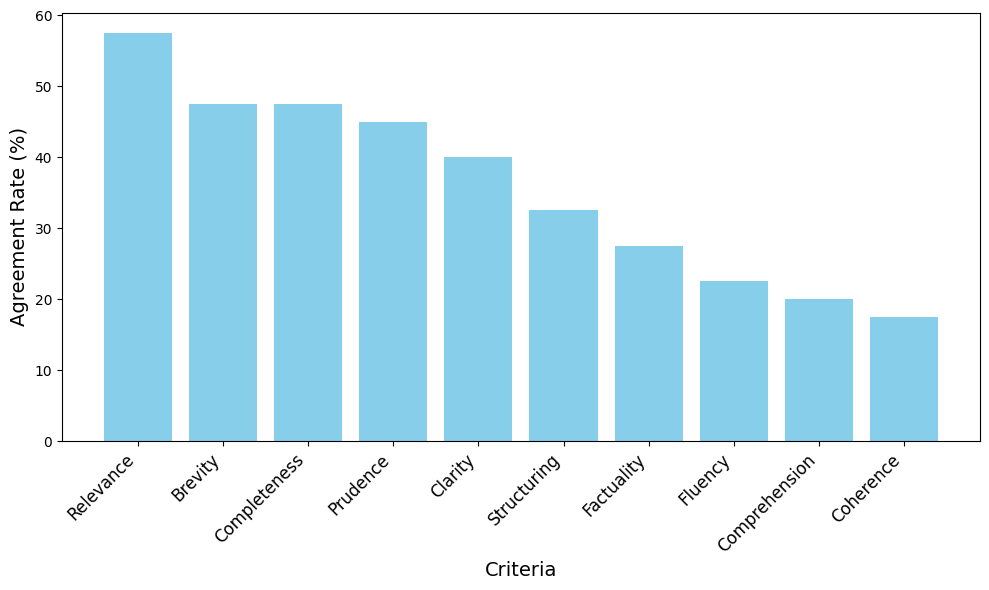

In [55]:
# Sort the data by Agreement_Rate (%) for better visualization
res_sorted = res_note_human_average.sort_values('Agreement_Rate (%)', ascending=False)

# Create the barplot
plt.figure(figsize=(10, 6))
plt.bar(res_sorted['Dimension'], res_sorted['Agreement_Rate (%)'], color='skyblue')
plt.xlabel('Criteria', fontsize=14)
plt.ylabel('Agreement Rate (%)', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.tight_layout()

save_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Figures\High dpi paper for technical check\Figure 5.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')

# Show the plot
plt.show()

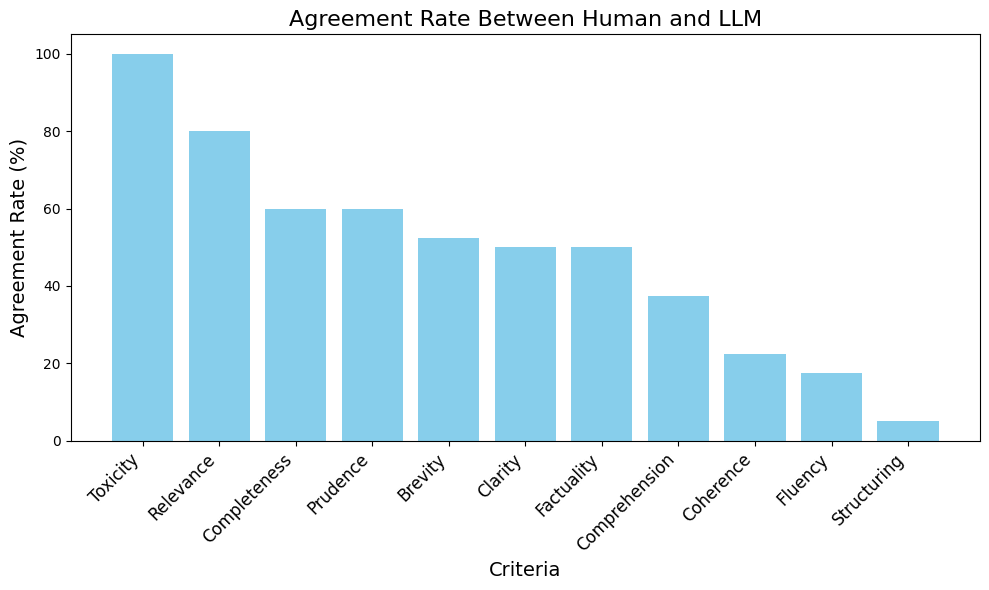

In [35]:
# Sort the data by Agreement_Rate (%) for better visualization
res_sorted = res_trans_human_a.sort_values('Agreement_Rate (%)', ascending=False)

# Create the barplot
plt.figure(figsize=(10, 6))
plt.bar(res_sorted['Dimension'], res_sorted['Agreement_Rate (%)'], color='skyblue')
plt.xlabel('Criteria', fontsize=14)
plt.ylabel('Agreement Rate (%)', fontsize=14)
plt.title('Agreement Rate Between Human and LLM', fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.tight_layout()

# Show the plot
plt.show()

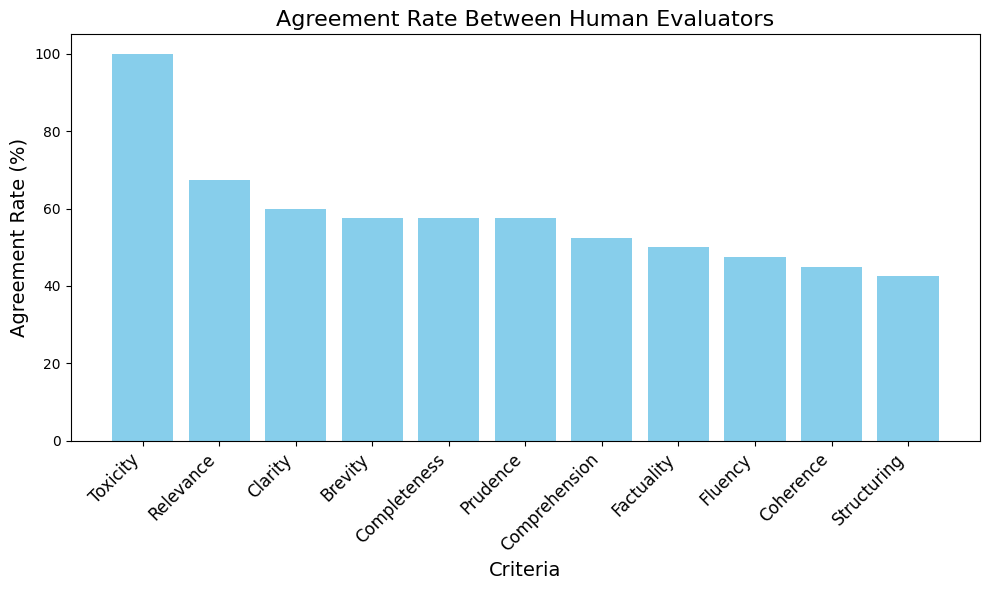

In [36]:
# Sort the data by Agreement_Rate (%) for better visualization
res_sorted = human_statistics_m_a.sort_values('Agreement_Rate (%)', ascending=False)

# Create the barplot
plt.figure(figsize=(10, 6))
plt.bar(res_sorted['Dimension'], res_sorted['Agreement_Rate (%)'], color='skyblue')
plt.xlabel('Criteria', fontsize=14)
plt.ylabel('Agreement Rate (%)', fontsize=14)
plt.title('Agreement Rate Between Human Evaluators', fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.tight_layout()

# Show the plot
plt.show()

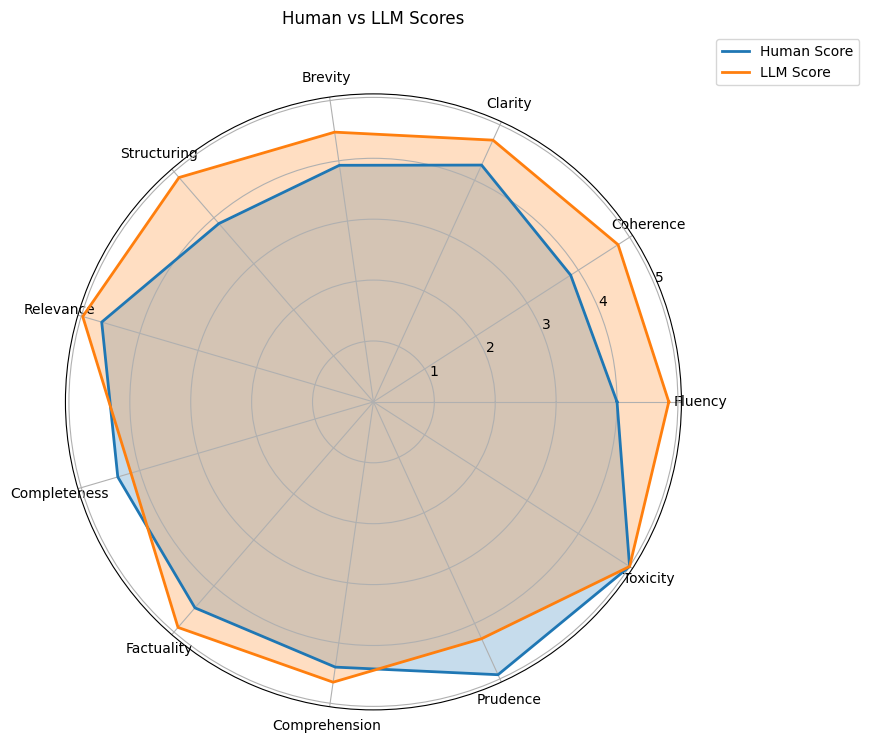

In [37]:
column_mapping = {
    'Fluency': 'Linguistic Quality_Fluency_Score',
    'Coherence': 'Linguistic Quality_Coherence_Score',
    'Clarity': 'Linguistic Quality_Clarity_Score',
    'Brevity': 'Linguistic Quality_Brevity_Score',
    'Structuring': 'Linguistic Quality_Structuring_Score',
    'Relevance': 'Content Integrity_Relevance_Score',
    'Completeness': 'Content Integrity_Completeness_Score',
    'Factuality': 'Content Integrity_Factuality_Score',
    'Comprehension': 'Content Integrity_Comprehension_Score',
    'Prudence': 'Trustworthiness_Prudence_Score',
    'Toxicity': 'Trustworthiness_Toxicity_Score'
}

# Select only relevant columns from df_m and llm_trans_note_eval
df_m_selected = df_m[list(column_mapping.keys())]
llm_selected = llm_trans_note_eval[list(column_mapping.values())]

llm_scores_avg = llm_selected.mean()
# Select only the relevant columns from df_m and llm_trans_note_eval
df_m_selected = df_m[list(column_mapping.keys())]
llm_selected = llm_trans_note_eval[list(column_mapping.values())]

# Calculate average scores
df_m_avg = df_m_selected.mean()
llm_scores_avg = llm_selected.mean()

# Align scores for radar chart
human_scores = df_m_avg
llm_scores = llm_scores_avg

# Radar chart setup
labels = list(column_mapping.keys())
num_vars = len(labels)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop

# Radar chart data
human_scores = human_scores.tolist()
llm_scores = llm_scores.tolist()

# Complete the loop for radar chart
human_scores += human_scores[:1]
llm_scores += llm_scores[:1]

# Plot radar chart
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.plot(angles, human_scores, label='Human Score', linewidth=2)
ax.fill(angles, human_scores, alpha=0.25)
ax.plot(angles, llm_scores, label='LLM Score', linewidth=2)
ax.fill(angles, llm_scores, alpha=0.25)

# Add labels
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

# Add legend
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

# Add title
plt.title("Human vs LLM Scores", y=1.1)
plt.show()

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\2844977448.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  human_scores = df_m_avg.tolist() + [df_m_avg[0]]  # Add first score at the end to close the loop
C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\2844977448.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  llm_scores = llm_scores_avg.tolist() + [llm_scores_avg[0]]
C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\2844977448.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataF

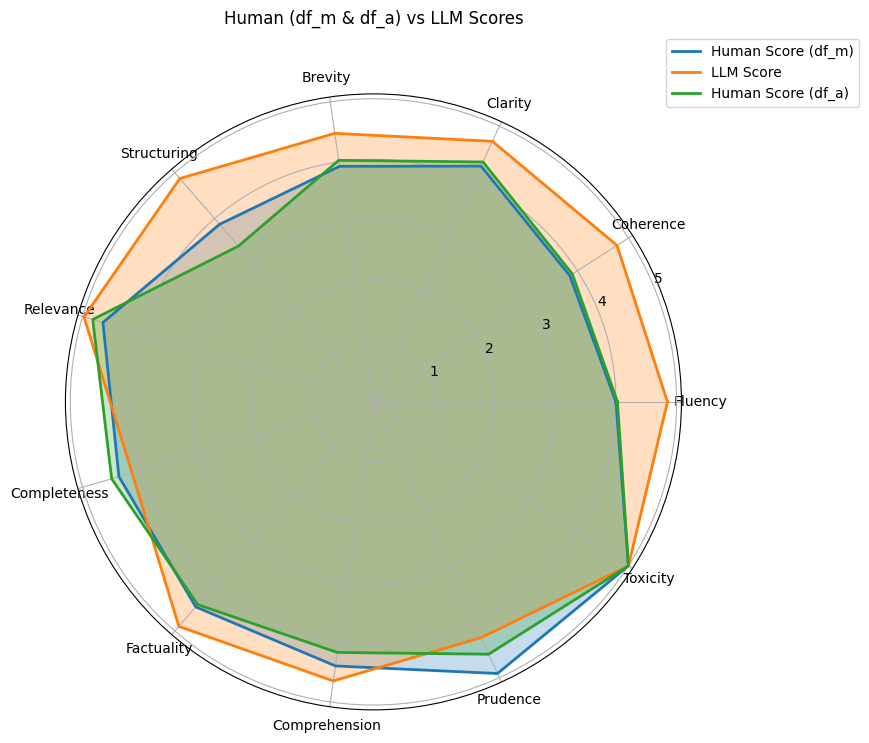

In [38]:
# Select only relevant columns from df_a
df_a_selected = df_a[list(column_mapping.keys())]

# Calculate average scores for df_a
df_a_avg = df_a_selected.mean()

# Align scores for radar chart
human_scores = df_m_avg.tolist() + [df_m_avg[0]]  # Add first score at the end to close the loop
llm_scores = llm_scores_avg.tolist() + [llm_scores_avg[0]]
df_a_scores = df_a_avg.tolist() + [df_a_avg[0]]

# Radar chart setup
labels = list(column_mapping.keys())
num_vars = len(labels)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop

# Plot radar chart
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.plot(angles, human_scores, label='Human Score (df_m)', linewidth=2)
ax.fill(angles, human_scores, alpha=0.25)

ax.plot(angles, llm_scores, label='LLM Score', linewidth=2)
ax.fill(angles, llm_scores, alpha=0.25)

ax.plot(angles, df_a_scores, label='Human Score (df_a)', linewidth=2)
ax.fill(angles, df_a_scores, alpha=0.25)

# Add labels
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

# Add legend
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

# Add title
plt.title("Human (df_m & df_a) vs LLM Scores", y=1.1)
plt.show()

C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_3372\3551935699.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  average_scores = df_avg_scores.tolist() + [df_avg_scores[0]]  # Add first score at the end to close the loop


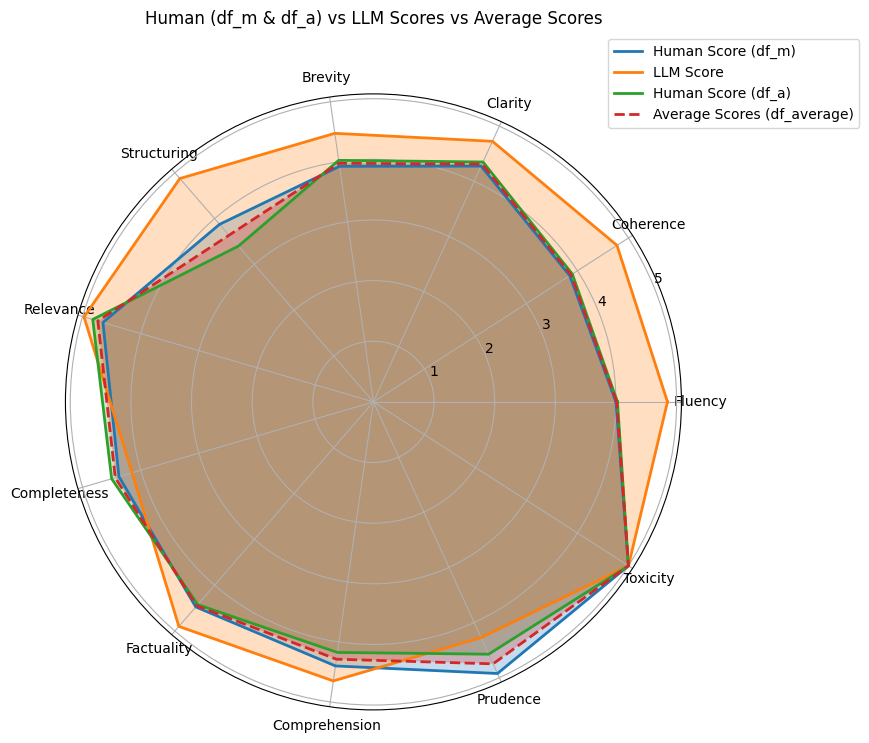

In [39]:
# Select only relevant columns for df_average
df_avg_selected = df_average[list(column_mapping.keys())]

# Calculate average scores for df_average
df_avg_scores = df_avg_selected.mean()

# Align scores for radar chart
average_scores = df_avg_scores.tolist() + [df_avg_scores[0]]  # Add first score at the end to close the loop

# Radar chart setup
labels = list(column_mapping.keys())
num_vars = len(labels)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop

# Plot radar chart
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.plot(angles, human_scores, label='Human Score (df_m)', linewidth=2)
ax.fill(angles, human_scores, alpha=0.25)

ax.plot(angles, llm_scores, label='LLM Score', linewidth=2)
ax.fill(angles, llm_scores, alpha=0.25)

ax.plot(angles, df_a_scores, label='Human Score (df_a)', linewidth=2)
ax.fill(angles, df_a_scores, alpha=0.25)

ax.plot(angles, average_scores, label='Average Scores (df_average)', linewidth=2, linestyle='--')
ax.fill(angles, average_scores, alpha=0.25)

# Add labels
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

# Add legend
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

# Add title
plt.title("Human (df_m & df_a) vs LLM Scores vs Average Scores", y=1.1)
plt.show()


# Emsemble score

## Calculate Automated Metric for GPT Note

In [40]:
# File path
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\metric_df.csv"

# Read the CSV file
metric_result_df = pd.read_csv(file_path)
metric_result_df.head(10)

,name,gpt_note,llama_note,transcript,reference_note,gpt_word_count,llama_word_count,transcript_word_count,gpt_char_count,llama_char_count,...,llama_bleu1,llama_bleu2,llama_bleu3,llama_bleu_cum,gpt_metero,llama_metero,bertscore_gpt,bertscore_llama,gpt_note_toxicity,llama_note_toxicity
0,DC0034 - DPt0329,**SOAP Note**\n\n**Patient Information:**\n- N...,**Subjective**\n\n* Patient reports anxiety an...,My name is Person 1. It's nice to meet you guy...,**SOAP Note**\n\n**Patient Information:**\n- N...,565,204,6336,4006,1393,...,0.071254,0.028764,0.012053,0.006297,1.000000,0.782609,0.987492,0.823234,0.025143,0.066258
1,PC0028 - PPt0503,**SOAP Note**\n\n**Patient Information:**\n- N...,**Subjective**\n\n* The patient presents for a...,Green dot you and so I was like is she ready? ...,**SOAP Note**\n\n**Patient Information:**\n- N...,476,412,4266,3370,2729,...,0.272375,0.122871,0.067086,0.036270,0.968254,0.784615,0.934152,0.845164,0.047359,0.080906
2,PC0074 - PPt0468,**SOAP Note:**\n\n**Subjective:**\n- Patient r...,"Here is a summary of the transcript, accuratel...","How are you? Good, how are you? Good, I'm Dr. ...",**SOAP Note:**\n\n**Subjective:**\n- Patient r...,294,318,1233,1917,1999,...,0.361635,0.168879,0.083578,0.020362,0.933333,0.777778,0.956375,0.868949,0.049793,0.086675
3,PC0072 - PPt0389,**SOAP Note**\n\n**Patient:** [Name]\n**Date:*...,Here is a summarized version of the transcript...,"I'm Person 2, I'm the supervising doctor. Than...",**SOAP Note**\n\n**Patient:** [Name]\n**Date:*...,512,271,1157,3430,1785,...,0.228503,0.121823,0.068541,0.036903,0.833333,0.796875,0.936480,0.840848,0.032918,0.077811
4,PC0068 - PPt0423,**Subjective:**\n- The patient is currently 20...,"Here is a summary of the transcript, accuratel...",Person 2. Hi guys. Oh my goodness. I know it's...,**Subjective:**\n- The patient is currently 20...,504,282,4222,3452,1767,...,0.157102,0.049417,0.008526,0.003321,0.926471,0.716418,0.943961,0.829589,0.077524,0.084177
5,PC0070 - PPt0518,**SOAP Note**\n\n**Subjective:**\n- Patient st...,Here is a summarized version of the transcript...,"Hey. Hello. Person 1? Person 1. How are you, P...",**SOAP Note**\n\n**Subjective:**\n- Patient st...,327,297,1153,2192,1803,...,0.363636,0.168094,0.085234,0.037391,0.951613,0.885246,0.954305,0.862549,0.062039,0.076968
6,PC0074 - PPt0448,**SOAP Note**\n\n**Patient Name:** [Not Provid...,"Here is a summary of the transcript, accuratel...",it's disgusting yeah I'm Dr. Person 4 how are ...,**SOAP Note**\n\n**Patient Name:** [Not Provid...,392,253,1348,2689,1692,...,0.302583,0.160222,0.101528,0.068326,0.984127,0.784615,0.942155,0.866184,0.036133,0.057021
7,DC0085 - DPt0631,**Subjective:**\n- Patient presents for a pren...,**SOAP Summary**\n\n**Subjective (S)**:\n\n* T...,Hello. Hi. How are you? Good. How are you? Goo...,**Subjective:**\n- Patient presents for a pren...,326,225,2954,2019,1377,...,0.171886,0.066418,0.035533,0.017664,0.857143,0.656716,0.967462,0.839083,0.013340,0.061883
8,DC0068 - DPt0567,"**SOAP Note**\n\n**Subjective:**\n- Patient, M...","Here is a summary of the transcript, classifie...","Hi, Ms. Person 10. Hello. Hello. You're not Ms...","**SOAP Note**\n\n**Subjective:**\n- Patient, M...",450,263,4328,2981,1604,...,0.160890,0.047098,0.016943,0.005432,0.983051,0.677966,0.987583,0.840876,0.058015,0.058135
9,DC0001 - DPt0411,**SOAP Note**\n\n**Subjective:**\n- Patient re...,Here is a summarized version of the transcript...,How are you doing today? I'm doing okay. Thank...,**SOAP Note**\n\n**Subjective:**\n- Patient re...,466,256,2326,3179,1621,...,0.131227,0.046487,0.017048,0.005517,0.984375,0.772727,0.959969,0.832372,0.031102,0.083169


In [41]:
metric_prep = metric_result_df[['name', 'gpt_note', 'llama_note', 'reference_note']].rename(
    columns={
        'name': 'file_name',
        'gpt_note': 'gpt_note',
        'llama_note': 'llama_note',
        'reference_note': 'reference_text'
    }
)

In [42]:
# Function to calculate toxicity
def calculate_toxicity(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
    scores = torch.nn.functional.softmax(outputs.logits, dim=-1)
    return scores[0][1].item()  # Toxicity score

# Function to calculate BLEU scores
def calculate_bleu(reference, candidate, n):
    smoothing = SmoothingFunction().method4
    weights = tuple([1.0 / n] * n) + tuple([0] * (4 - n))
    return sentence_bleu([reference.split()], candidate.split(), weights=weights, smoothing_function=smoothing)

# Function to calculate BLEU cumulative scores
def calculate_bleu_cumulative(reference, candidate):
    smoothing = SmoothingFunction().method4
    bleu1 = sentence_bleu([reference.split()], candidate.split(), weights=(1, 0, 0, 0), smoothing_function=smoothing)
    bleu2 = sentence_bleu([reference.split()], candidate.split(), weights=(0.5, 0.5, 0, 0), smoothing_function=smoothing)
    bleu3 = sentence_bleu([reference.split()], candidate.split(), weights=(0.33, 0.33, 0.33, 0), smoothing_function=smoothing)
    bleu4 = sentence_bleu([reference.split()], candidate.split(), weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothing)
    return bleu1, bleu2, bleu3, bleu4

# Function to calculate ROUGE scores
def calculate_rouge(reference, candidate):
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rouge3', 'rougeL'], use_stemmer=True)
    scores = scorer.score(reference, candidate)
    return scores

# Main function
def calculate_text_metrics(df, reference_col, text_cols):
    results = df.copy()
    for col in text_cols:
        rouge1_list, rouge2_list, rouge3_list, rougeL_list = [], [], [], []
        bleu1_list, bleu2_list, bleu3_list, bleu4_list = [], [], [], []
        bert_precision_list, bert_recall_list, bert_f1_list = [], [], []
        meteor_list = []
        toxicity_list = []

        for ref, text in tqdm(zip(results[reference_col], results[col]), total=len(results), desc=f"Processing {col}"):
            # ROUGE
            rouge_scores = calculate_rouge(ref, text)
            rouge1_list.append(rouge_scores['rouge1'].fmeasure)
            rouge2_list.append(rouge_scores['rouge2'].fmeasure)
            rouge3_list.append(rouge_scores['rouge3'].fmeasure)
            rougeL_list.append(rouge_scores['rougeL'].fmeasure)

            # BLEU
            bleu1_list.append(calculate_bleu(ref, text, 1))
            bleu2_list.append(calculate_bleu(ref, text, 2))
            bleu3_list.append(calculate_bleu(ref, text, 3))
            bleu4_list.append(calculate_bleu(ref, text, 4))

            # BLEU Cumulative
            bleu_cum1, bleu_cum2, bleu_cum3, bleu_cum4 = calculate_bleu_cumulative(ref, text)

            # METEOR
            try:
                meteor_list.append(meteor_score([ref.split()], text.split()))
            except:
                meteor_list.append(0.0)  # Handle empty texts

            # BERTScore
            P, R, F1 = bert_score([text], [ref], lang="en", verbose=False)
            bert_precision_list.append(P.mean().item())
            bert_recall_list.append(R.mean().item())
            bert_f1_list.append(F1.mean().item())

            # Toxicity
            toxicity_list.append(calculate_toxicity(text))

        # Append results as new columns
        results[f'{col}_rouge1'] = rouge1_list
        results[f'{col}_rouge2'] = rouge2_list
        results[f'{col}_rouge3'] = rouge3_list
        results[f'{col}_rougeL'] = rougeL_list
        results[f'{col}_bleu1'] = bleu1_list
        results[f'{col}_bleu2'] = bleu2_list
        results[f'{col}_bleu3'] = bleu3_list
        results[f'{col}_bleu4'] = bleu4_list
        results[f'{col}_meteor'] = meteor_list
        results[f'{col}_bert_precision'] = bert_precision_list
        results[f'{col}_bert_recall'] = bert_recall_list
        results[f'{col}_bert_f1'] = bert_f1_list
        results[f'{col}_toxicity'] = toxicity_list

    return results


In [ ]:
# Calculation of automated score from LLaMA and GPT with out repeat. This is omitted since it is saved

# note_columns = [col for col in metric_prep.columns if 'note' in col]
# # Run the `calculate_text_metrics` function for the notes columns
# metric_results_df = calculate_text_metrics(metric_prep, reference_col='reference_text', text_cols=note_columns)

# metric_results_df.head(10)

In [47]:
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\gpt_llama_auto_result_no_repeat.csv"

# Re-import the DataFrame
metric_results_df = pd.read_csv(file_path)

## Join the Automated Metric Results with Human Evaluation Results

In [48]:
merged_df = pd.merge(df_m, metric_results_df, left_on='Document Number', right_on='file_name', how='inner')
print(merged_df.columns)

Index(['Document Number', 'Fluency', 'Coherence', 'Clarity', 'Brevity',
       'Structuring', 'Relevance', 'Completeness', 'Factuality',
       'Comprehension', 'Prudence', 'Toxicity', 'Note', 'Evaluation Time',
       'Editing Time', 'Linguistic Average Score', 'Content Average Score',
       'file_name', 'gpt_note', 'llama_note', 'reference_text',
       'gpt_note_rouge1', 'gpt_note_rouge2', 'gpt_note_rouge3',
       'gpt_note_rougeL', 'gpt_note_bleu1', 'gpt_note_bleu2', 'gpt_note_bleu3',
       'gpt_note_bleu4', 'gpt_note_meteor', 'gpt_note_bert_precision',
       'gpt_note_bert_recall', 'gpt_note_bert_f1', 'gpt_note_toxicity',
       'llama_note_rouge1', 'llama_note_rouge2', 'llama_note_rouge3',
       'llama_note_rougeL', 'llama_note_bleu1', 'llama_note_bleu2',
       'llama_note_bleu3', 'llama_note_bleu4', 'llama_note_meteor',
       'llama_note_bert_precision', 'llama_note_bert_recall',
       'llama_note_bert_f1', 'llama_note_toxicity'],
      dtype='object')


## Predicted Dimentions based on Automated Metrics

In [49]:
# Define human score dimensions and GPT metrics
human_scores = ['Fluency', 'Coherence', 'Clarity', 'Brevity',
                'Structuring', 'Relevance', 'Completeness', 'Factuality',
                'Comprehension', 'Prudence']
gpt_metrics = ['gpt_note_rouge1', 'gpt_note_rouge2', 'gpt_note_rouge3',
               'gpt_note_rougeL', 'gpt_note_bleu1', 'gpt_note_bleu2',
               'gpt_note_bleu3', 'gpt_note_bleu4', 'gpt_note_meteor',
               'gpt_note_bert_precision', 'gpt_note_bert_recall',
               'gpt_note_bert_f1']

# Prepare the dataset for regression
X = merged_df[gpt_metrics]

# Create a dictionary to store models and predictions
models = {}
predictions = {}

# Loop through each human score dimension
for score in human_scores:
    # Define the target variable
    y = merged_df[score]
    
    # Initialize and train the model
    model = LinearRegression()
    model.fit(X, y)
    
    # Predict on the entire dataset
    y_pred = model.predict(X)
    
    # Scale predictions to the range [1, 5]
    scaler = MinMaxScaler(feature_range=(0, 5))
    y_pred_scaled = scaler.fit_transform(y_pred.reshape(-1, 1)).flatten()
    
    # Store the model and scaled predictions
    models[score] = model
    predictions[score] = y_pred_scaled
    
    # Evaluate the model (optional, for reference only)
    mse = mean_squared_error(y, y_pred_scaled)
    print(f'MSE for {score}: {mse}')

# Append the predicted dimensions to the original dataframe
for score in human_scores:
    merged_df[f'Predicted_{score}'] = predictions[score]

MSE for Fluency: 1.7785514706606513
MSE for Coherence: 2.044520533285023
MSE for Clarity: 3.458221552027651
MSE for Brevity: 1.7943935697781748
MSE for Structuring: 1.8037660377020195
MSE for Relevance: 3.9164159632206337
MSE for Completeness: 4.662848997060847
MSE for Factuality: 2.9267119536078328
MSE for Comprehension: 2.8215810261060135
MSE for Prudence: 2.8475457079423263


In [50]:
merged_df['Predicted_Toxicity'] = 5

The toxic bert ranges from 0 to 1, and all of the predicted toxicity score are below 0.1

## Prepare Data for Radar Plot

In [51]:
metric_dict = {
    column.replace("Predicted_", ""): merged_df[column].mean()
    for column in merged_df.columns if column.startswith("Predicted_")
}

# Display the dictionary
print(metric_dict)

{'Fluency': 2.9235531907746983, 'Coherence': 2.6672487824857294, 'Clarity': 2.667533222641393, 'Brevity': 2.8355239798988676, 'Structuring': 2.707485336376563, 'Relevance': 2.89443765559408, 'Completeness': 2.6155378777226685, 'Factuality': 3.0969137174430315, 'Comprehension': 3.056772268877546, 'Prudence': 3.344772654554505, 'Toxicity': 5.0}


In [52]:
columns_to_average = ['Fluency', 'Coherence', 'Clarity', 'Brevity', 
                      'Structuring', 'Relevance', 'Completeness', 'Factuality',
                      'Comprehension', 'Prudence', 'Toxicity']

# Calculate the mean for each column and store in a dictionary
human_dict = {col: df_m[col].mean() for col in columns_to_average}

# Print the dictionary
print(human_dict)

{'Fluency': 4.0, 'Coherence': 3.85, 'Clarity': 4.275, 'Brevity': 3.925, 'Structuring': 3.875, 'Relevance': 4.65, 'Completeness': 4.375, 'Factuality': 4.475, 'Comprehension': 4.4, 'Prudence': 4.925, 'Toxicity': 5.0}


In [53]:
# Define the mapping of keys to column names
column_mapping = {
    'Fluency': 'Linguistic Quality_Fluency_Score',
    'Coherence': 'Linguistic Quality_Coherence_Score',
    'Clarity': 'Linguistic Quality_Clarity_Score',
    'Brevity': 'Linguistic Quality_Brevity_Score',
    'Structuring': 'Linguistic Quality_Structuring_Score',
    'Relevance': 'Content Integrity_Relevance_Score',
    'Completeness': 'Content Integrity_Completeness_Score',
    'Factuality': 'Content Integrity_Factuality_Score',
    'Comprehension': 'Content Integrity_Comprehension_Score',
    'Prudence': 'Trustworthiness_Prudence_Score',
    'Toxicity': 'Trustworthiness_Toxicity_Score'
}

# Calculate the mean for each column and store in a dictionary with the specified keys
llm_dict = {key: llm_trans_note_eval[column].mean() for key, column in column_mapping.items()}

# Print the dictionary
print(llm_dict)

{'Fluency': 4.85, 'Coherence': 4.775, 'Clarity': 4.725, 'Brevity': 4.475, 'Structuring': 4.875, 'Relevance': 4.975, 'Completeness': 4.15, 'Factuality': 4.9, 'Comprehension': 4.65, 'Prudence': 4.275, 'Toxicity': 5.0}


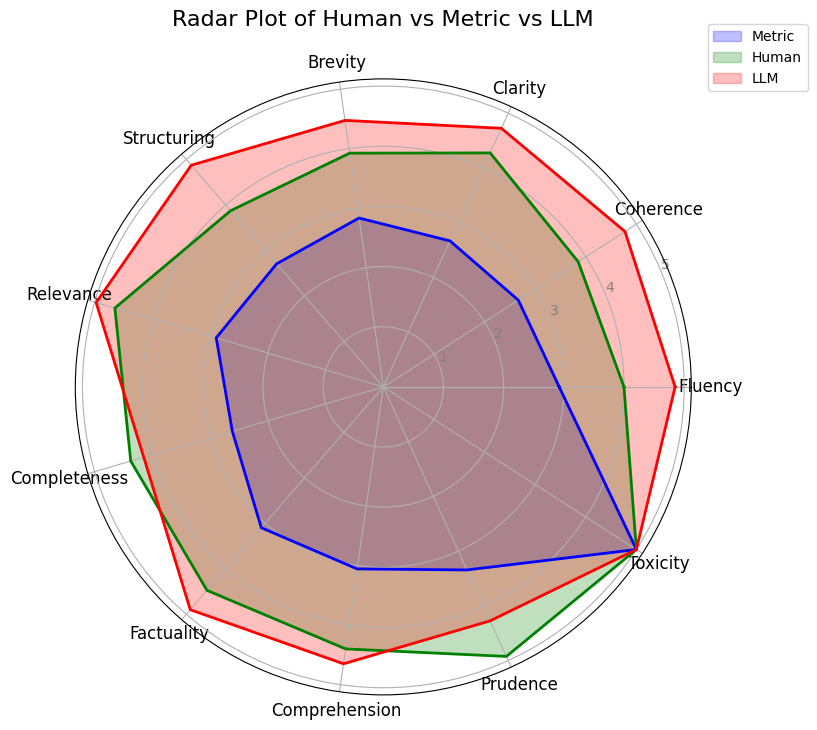

In [54]:
# Prepare data for radar plot
categories = list(metric_dict.keys())
values_metric = list(metric_dict.values())
values_human = list(human_dict.values())
values_llm = list(llm_dict.values())

# Close the plot by repeating the first value
values_metric.append(values_metric[0])
values_human.append(values_human[0])
values_llm.append(values_llm[0])

# Convert categories into angles
angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
angles += [angles[0]]  # Closing the radar chart

# Plot
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'projection': 'polar'})

# Add the filled areas
ax.fill(angles, values_metric, color='blue', alpha=0.25, label='Metric')
ax.fill(angles, values_human, color='green', alpha=0.25, label='Human')
ax.fill(angles, values_llm, color='red', alpha=0.25, label='LLM')

# Add the outlines
ax.plot(angles, values_metric, color='blue', linewidth=2)
ax.plot(angles, values_human, color='green', linewidth=2)
ax.plot(angles, values_llm, color='red', linewidth=2)

# Customize the plot
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(['1', '2', '3', '4', '5'], fontsize=10, color='grey')
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)

# Title and legend
plt.title('Radar Plot of Human vs Metric vs LLM', fontsize=16, pad=20)
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1))
plt.show()
